# Countiles: U.S. county tiles

This notebook divides every county of the contiguous United States into tiles of about 15 x 15 miles that add up exactly to the county.

- Input: `reference/cb_2023_us_county_500k.zip` (U.S. Census Bureau cartographic boundary file, 2023, 1:500,000).
- Output: `map/countiles.geojson`.

The rules are all in one function called `countiles(county)`, which is applied iteratively to each county.

Code created by Andres Patrignani with the help of Claude code. November 17, 2026.

In [1]:
# Import modules
import math
from pathlib import Path
import geopandas as gpd
import numpy as np
import shapely
from pyproj import Geod
from shapely.geometry import MultiPolygon, box

In [ ]:
REFERENCE = Path("reference") / "cb_2023_us_county_500k.zip"
OUTPUT = Path("map") / "countiles.geojson"
NOT_CONTIGUOUS = {"02", "15", "60", "66", "69", "72", "78"}   # Alaska, Hawaii and the territories (state FIPS)

## Tile size

The aim is a tile of about 15 x 15 miles. Counties differ in size and shape, so a tile may be as large as 20 x 20 miles and as small as 10 x 10 miles, and no more than twice as long as it is wide.

In [2]:
# Constants
MILE_KM = 1.609344
LARGEST_KM = 20 * MILE_KM          # longest side of a tile
SMALLEST_KM = 10 * MILE_KM         # shortest side of a tile
MAX_KM2 = LARGEST_KM ** 2          # largest tile, 20 x 20 miles
MIN_KM2 = SMALLEST_KM ** 2         # smallest tile, 10 x 10 miles
MAX_ASPECT = 2                     # long side / short side

# Two tolerances to apply the rules to digitized county lines, which wobble
LINE_KM = 0.5                      # a stretch is straight if it stays within this of a line
TOUCH_DEG = 0.001                  # two pieces touch if they are within about 100 m

KM_PER_DEG = 111.32                # km per degree of latitude
GEOD = Geod(ellps="GRS80")

## Helpers

Small geometric tools used by the rules: the area of a shape, its polygon parts, the proportions of its bounding box, and the length of county line that runs along each meridian and parallel.

In [3]:
def area_km2(geom):
    """Geodesic area of a lon/lat geometry."""
    return abs(GEOD.geometry_area_perimeter(geom)[0]) / 1e6


def polygons(geom):
    """Polygon parts of a geometry."""
    geom = shapely.make_valid(geom)
    return [g for g in getattr(geom, "geoms", [geom]) if g.geom_type == "Polygon" and g.area > 0]


def aspect(geom):
    """Long side / short side of a geometry's bounding box, in km."""
    west, south, east, north = geom.bounds
    w = (east - west) * KM_PER_DEG * math.cos(math.radians((south + north) / 2))
    h = (north - south) * KM_PER_DEG
    return max(w / h, h / w)


def straight_stretches(county, km_per_deg_lon):
    """Length (km) of county line along each meridian and each parallel.

    Returns {longitude: km} and {latitude: km}: for every band LINE_KM wide, the
    length of county line that runs inside it, at the band's mean position.
    """
    ns, ew = [], []                                        # (position km, length km)
    for poly in polygons(county):
        for ring in [poly.exterior, *poly.interiors]:
            xy = np.asarray(ring.coords)
            for (x1, y1), (x2, y2) in zip(xy[:-1], xy[1:]):
                dx, dy = abs(x2 - x1) * km_per_deg_lon, abs(y2 - y1) * KM_PER_DEG
                if dx <= LINE_KM and dy > 0:
                    ns.append(((x1 + x2) / 2 * km_per_deg_lon, dy))
                if dy <= LINE_KM and dx > 0:
                    ew.append(((y1 + y2) / 2 * KM_PER_DEG, dx))

    def bands(segments, k):
        segments.sort()
        pos = np.array([p for p, _ in segments])
        along = np.array([a for _, a in segments])
        total, moment = np.r_[0, np.cumsum(along)], np.r_[0, np.cumsum(along * pos)]
        lo = np.arange(len(pos))
        hi = np.searchsorted(pos, pos + LINE_KM, side="right")     # band starting at each segment
        length = total[hi] - total[lo]
        return {(moment[h] - moment[l]) / n / k: n for l, h, n in zip(lo, hi, length)}

    return bands(ns, km_per_deg_lon), bands(ew, KM_PER_DEG)

## The rules

1. **Break lines.** A straight north-south or east-west stretch of the county line that is at least 10 miles long and at least 10 miles inside the county's bounding box becomes a grid line. If two lines are closer than 10 miles, the longer is kept.
2. **Grid.** Between break lines, add the fewest evenly spaced lines that keep cells within 20 miles on a side. The county is first measured as the rectangle of its own area and proportions. If a tile comes out larger than 20 x 20 miles, the grid is refined up to the full bounding box.
3. **Cut.** Cells are clipped to the county and every separate piece is a tile.
4. **Merge.** A piece smaller than 10 x 10 miles, or more than twice as long as wide, joins the tile it shares the longest border with, starting from the smallest first.
5. **Number.** Tiles are numbered in reading order: north to south and west to east.

In [4]:
def countiles(county):
    """Tiles of one county (a lon/lat polygon), in reading order."""
    west, south, east, north = county.bounds
    kx = KM_PER_DEG * math.cos(math.radians((south + north) / 2))    # km per degree of longitude
    ky = KM_PER_DEG

    # Rule 1. Break lines: the box edges and the long straight stretches between them
    def break_lines(lo, hi, stretches, k):
        inside = sorted(((length, pos) for pos, length in stretches.items()
                         if length >= SMALLEST_KM and (pos - lo) * k >= SMALLEST_KM
                         and (hi - pos) * k >= SMALLEST_KM), reverse=True)
        keep = []
        for _, pos in inside:                               # longest first
            if all(abs(pos - q) * k >= SMALLEST_KM for q in keep):
                keep.append(pos)
        return [lo] + sorted(keep) + [hi]

    ns, ew = straight_stretches(county, kx)
    xs0, ys0 = break_lines(west, east, ns, kx), break_lines(south, north, ew, ky)

    # Rule 2. Grid: evenly spaced lines between break lines, with lengths measured at `scale`
    def grid_lines(marks, k, scale):
        out = [marks[0]]
        for a, b in zip(marks[:-1], marks[1:]):
            n = max(1, math.ceil(scale * (b - a) * k / LARGEST_KM - 1e-9))
            out += list(np.linspace(a, b, n + 1)[1:])
        return out

    # Scales to try: from the rectangle of the county's area (area / box area, as
    # a length ratio) to the full box (1), stopping at each one that adds a line
    start = math.sqrt(area_km2(county) / ((east - west) * kx * (north - south) * ky))
    scales = {start, 1.0}
    for marks, k in ((xs0, kx), (ys0, ky)):
        for a, b in zip(marks[:-1], marks[1:]):
            length = (b - a) * k
            scales |= {j * LARGEST_KM / length * (1 + 1e-6) for j in range(1, math.ceil(length / LARGEST_KM) + 1)
                       if start < j * LARGEST_KM / length < 1}

    for scale in sorted(scales):
        xs, ys = grid_lines(xs0, kx, scale), grid_lines(ys0, ky, scale)

        # Rule 3. Cut: [polygon, area, elongated as cut] for every piece of every cell
        tiles = [[g, area_km2(g), aspect(g) > MAX_ASPECT]
                 for c in range(len(xs) - 1) for r in range(len(ys) - 1)
                 for g in polygons(county.intersection(box(xs[c], ys[r], xs[c + 1], ys[r + 1])))]

        # Rule 4. Merge: small or elongated pieces join the tile they share the longest border with
        while len(tiles) > 1:
            left = [t for t in tiles if t[1] < MIN_KM2 or t[2]]
            if not left:
                break
            small = min(left, key=lambda t: t[1])
            tiles.remove(small)
            halo = small[0].buffer(TOUCH_DEG)
            shared = [halo.intersection(t[0]).area for t in tiles]
            if max(shared) > 0:
                best = tiles[int(np.argmax(shared))]
            else:                                           # an island joins the nearest tile
                best = min(tiles, key=lambda t: small[0].distance(t[0]))
            parts = polygons(best[0].union(small[0]))
            best[0] = parts[0] if len(parts) == 1 else MultiPolygon(parts)
            best[1] += small[1]
            best[2] = False

        if max(t[1] for t in tiles) <= MAX_KM2 * (1 + 1e-3):    # no tile larger than 20 x 20 miles
            break
    tiles = [t[0] for t in tiles]

    # Rule 5. Number: tiles whose centers are within half a tile height form a row
    pts = [t.representative_point() for t in tiles]
    height = np.median([t.bounds[3] - t.bounds[1] for t in tiles])
    rows, top = [], None
    for i in sorted(range(len(tiles)), key=lambda i: -pts[i].y):
        if top is None or top - pts[i].y > 0.5 * height:
            rows.append([])
            top = pts[i].y
        rows[-1].append(i)
    return [tiles[i] for row in rows for i in sorted(row, key=lambda i: pts[i].x)]

## Reference counties

In [5]:
counties = gpd.read_file(REFERENCE).to_crs("EPSG:4326")
counties = counties[~counties.STATEFP.isin(NOT_CONTIGUOUS)]
counties = counties.rename(columns={"GEOID": "fips", "STUSPS": "state", "NAME": "county"})[["fips", "state", "county", "geometry"]]
counties = counties.sort_values("fips").reset_index(drop=True)
counties["geometry"] = counties.geometry.make_valid()
print(len(counties), "counties")

3109 counties


## Apply the rules to every county

This takes a few minutes.

In [6]:
rows = []
for c in counties.itertuples():
    tiles = countiles(c.geometry)
    for number, geom in enumerate(tiles, start=1):
        rows.append((f"{c.fips}-{number:02d}", c.fips, c.state, c.county, number, len(tiles), round(area_km2(geom), 1), geom))

tiles = gpd.GeoDataFrame(rows, columns=["id", "fips", "state", "county", "tile", "tiles_in_county", "area_km2", "geometry"],
                         crs="EPSG:4326")
print(len(tiles), "tiles; median area", round(tiles.area_km2.median()), "km2")

13140 tiles; median area 579 km2


## Save

Coordinates are placed on a lattice of five decimals (about 1 m), which keeps every tile a valid polygon.

In [7]:
tiles["geometry"] = shapely.set_precision(tiles.geometry.values, 1e-5)
OUTPUT.parent.mkdir(exist_ok=True)
tiles.to_file(OUTPUT, driver="GeoJSON", COORDINATE_PRECISION=5)
print(OUTPUT, round(OUTPUT.stat().st_size / 1e6, 1), "MB")

map\countiles.geojson 26.6 MB


## Check

tiles per county: {1: 380, 2: 713, 3: 424, 4: 1019, 5: 90, 6: 138, 7: 43, 8: 51}
larger than 20 x 20 miles: 77
smaller than 10 x 10 miles, in divided counties: 0
more than 2:1 (bounding box), in divided counties: 167


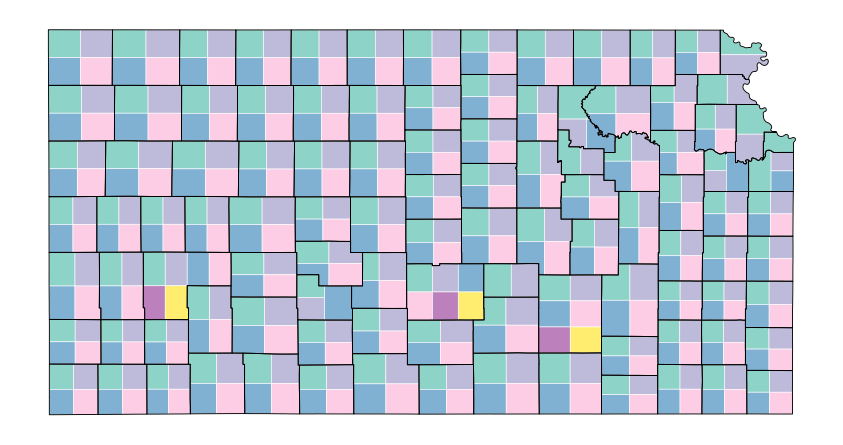

In [8]:
split = tiles.tiles_in_county > 1
side = np.array([aspect(g) for g in tiles.geometry])
print("tiles per county:", tiles.groupby("fips").size().value_counts().sort_index().head(8).to_dict())
print("larger than 20 x 20 miles:", int((tiles.area_km2 > MAX_KM2 * 1.001).sum()))
print("smaller than 10 x 10 miles, in divided counties:", int(((tiles.area_km2 < MIN_KM2 * 0.999) & split).sum()))
print("more than 2:1 (bounding box), in divided counties:", int(((side > MAX_ASPECT) & split).sum()))

ax = tiles[tiles.state == "KS"].plot(column="tile", cmap="Set3", edgecolor="white", linewidth=0.4, figsize=(10, 5))
counties[counties.state == "KS"].boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.set_axis_off()